# GROUP41 - Assignment 1: EDA ve Baseline

**Kaggle:** CSIRO - Image2Biomass Prediction

**Takım:** Bilgehan Akbaş, Ömer Nuri Zaimoğlu

**Amaç:** Mera fotoğraflarından 5 biomass değerini tahmin etmek. Bu notebook'ta veriyi inceliyor ve baseline modelleri karşılaştırıyoruz.

In [1]:
import os, sys

REPO = "GROUP41_CENG313"
if not os.path.exists(REPO):
    !git clone -q https://github.com/OmerNuriZ/{REPO}.git
else:
    !git -C {REPO} pull -q

sys.path.insert(0, f"{REPO}/src")

In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip -q install -U kaggle
!kaggle competitions download -c csiro-biomass -p data
!unzip -q -o data/csiro-biomass.zip -d data
!ls data

csiro-biomass.zip: Skipping, found more recently modified local copy (use --force to force download)
csiro-biomass.zip  sample_submission.csv  test	test.csv  train  train.csv


In [3]:
import pandas as pd
from data import load_train

df = load_train("data/train.csv")
print(df.shape)
df.head()

(357, 11)


,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,Dry_Green_g,Dry_Dead_g,Dry_Clover_g,GDM_g,Dry_Total_g
0,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,16.2751,31.9984,0.0000,16.2750,48.2735
1,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,7.6000,0.0000,0.0000,7.6000,7.6000
2,train/ID1025234388.jpg,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000,0.0000,0.0000,6.0500,6.0500,6.0500
3,train/ID1028611175.jpg,2015/5/18,Tas,Ryegrass,0.66,5.0000,24.2376,30.9703,0.0000,24.2376,55.2079
4,train/ID1035947949.jpg,2015/9/11,Tas,Ryegrass,0.54,3.5000,10.5261,23.2239,0.4343,10.9605,34.1844


## 1. Veri Kalitesi Kontrolü

In [4]:
from data import TARGETS

raw = pd.read_csv("data/train.csv")
print("Eksik değer:", raw.isna().sum().sum())
print("Tekrarlanan satır:", raw.duplicated().sum())
print("Görüntü başına hedef sayısı:", raw.groupby("image_path").size().unique())
print("Negatif hedef:", (df[TARGETS] < 0).sum().sum())

clover_adi = df["Species"].str.contains("clover", case=False)
print("Adında Clover yok ama clover > 0:", ((df["Dry_Clover_g"] > 0) & ~clover_adi).sum())
print("Adında Clover var ama clover = 0:", ((df["Dry_Clover_g"] == 0) & clover_adi).sum())

Eksik değer: 0
Tekrarlanan satır: 0
Görüntü başına hedef sayısı: [5]
Negatif hedef: 0
Adında Clover yok ama clover > 0: 24
Adında Clover var ama clover = 0: 27


**Yorum:**
- Eksik değer, tekrar eden satır ve negatif değer yok. Her görüntüde 5 hedef var.
- Species etiketi baskın türü gösteriyor, kesin içeriği değil. Adında Clover geçmeyen 24 örnekte clover var, geçen 27 örnekte yok.
- Aykırı değerler hata değil, gerçekten yoğun çayırlar. Silmiyoruz.

## 2. Target Analizi

In [5]:
print(df[TARGETS].describe().round(1))
print("\nSıfır oranları:")
print((df[TARGETS] == 0).mean().round(3))

       Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
count        357.0       357.0         357.0  357.0        357.0
mean          26.6        12.0           6.6   33.3         45.3
std           25.4        12.4          12.1   24.9         28.0
min            0.0         0.0           0.0    1.0          1.0
25%            8.8         3.2           0.0   16.0         25.3
50%           20.8         8.0           1.4   27.1         40.3
75%           35.1        17.6           7.2   43.7         57.9
max          158.0        83.8          71.8  158.0        185.7

Sıfır oranları:
Dry_Green_g     0.050
Dry_Dead_g      0.112
Dry_Clover_g    0.378
GDM_g           0.000
Dry_Total_g     0.000
dtype: float64


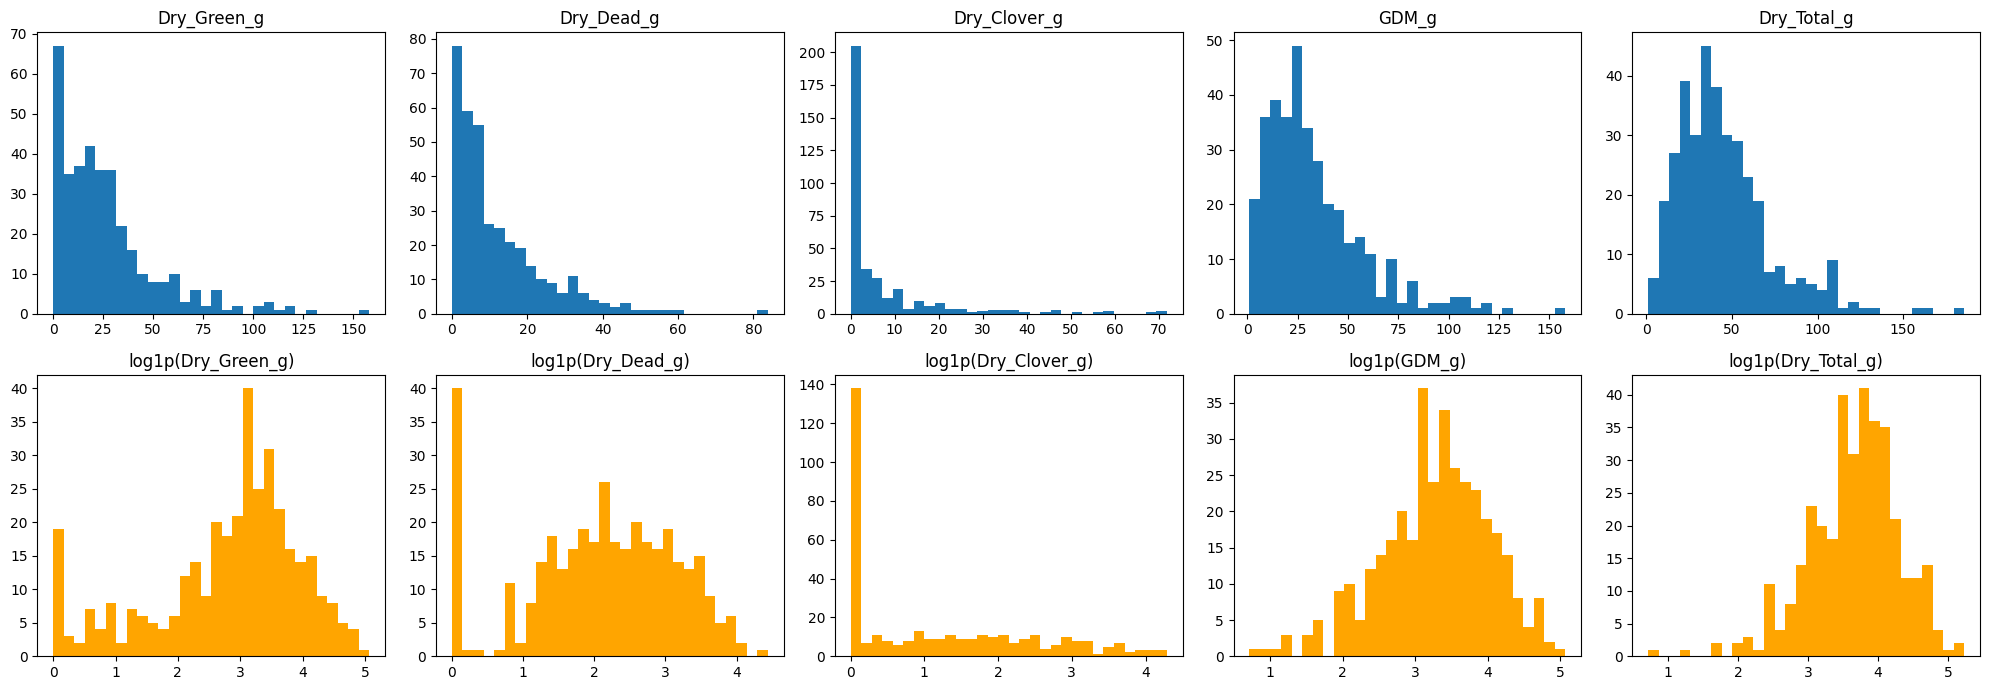

In [6]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 5, figsize=(20, 7))
for i, t in enumerate(TARGETS):
    ax[0, i].hist(df[t], bins=30)
    ax[0, i].set_title(t)
    ax[1, i].hist(np.log1p(df[t]), bins=30, color="orange")
    ax[1, i].set_title(f"log1p({t})")
plt.tight_layout()
plt.show()

**Yorum:**
- Tüm hedefler sağa çarpık: Dry_Total medyan 40.3 g, max 185.7 g
- Log1p sonrası GDM ve Dry_Total neredeyse simetrik, modelleri log ölçeğinde eğitmeliyiz.
- Dry_Green ve Dry_Dead'de 0'da ayrı bir yığılma var.
- Dry_Clover'ın %37.8'i sıfır, en zor hedef bu olacak.

## 3. Hedefler Arası İlişki

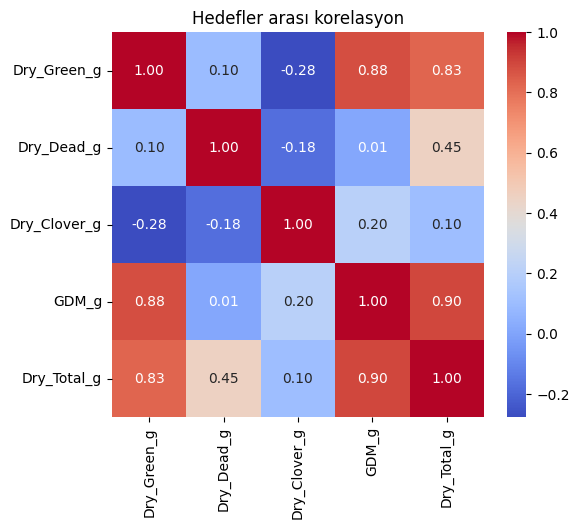

In [7]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(df[TARGETS].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Hedefler arası korelasyon")
plt.show()

In [8]:
fark_total = df["Dry_Total_g"] - (df["Dry_Green_g"] + df["Dry_Dead_g"] + df["Dry_Clover_g"])
fark_gdm = df["GDM_g"] - (df["Dry_Green_g"] + df["Dry_Clover_g"])

print("Total - (Green+Dead+Clover) max fark:", round(fark_total.abs().max(), 3))
print("GDM - (Green+Clover) max fark:", round(fark_gdm.abs().max(), 3))

Total - (Green+Dead+Clover) max fark: 0.309
GDM - (Green+Clover) max fark: 0.0


**Yorum:**
- Dry_Total = Green + Dead + Clover (max fark 0.31 g), GDM = Green + Clover (fark 0).
- Yani 5 hedefin aslında 3'ü bağımsız, diğer ikisi toplamdan geliyor.
- En güçlü korelasyon GDM ile Total arasında (0.90), sonra Green ile GDM (0.88).
- Clover diğerlerinden ayrı davranıyor, korelasyonları zayıf hatta negatif.

## 4. Metadata Analizi
Bu alanlar sadece train'de var, test'te yok. Model yalnızca görüntüyü görecek.

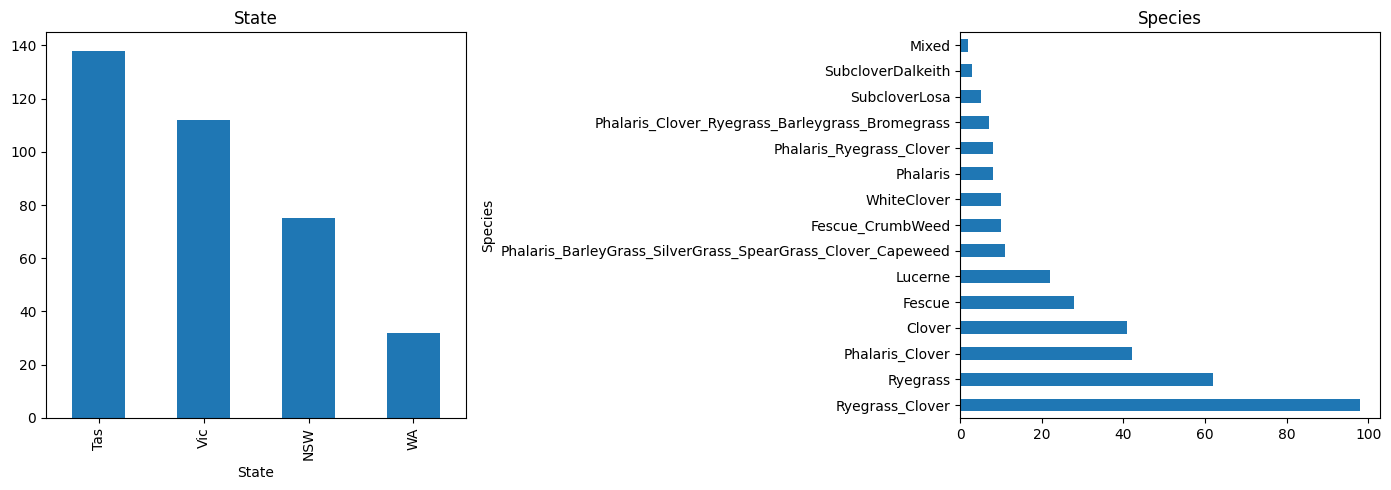

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df["State"].value_counts().plot.bar(ax=ax[0], title="State")
df["Species"].value_counts().plot.barh(ax=ax[1], title="Species")
plt.tight_layout()
plt.show()

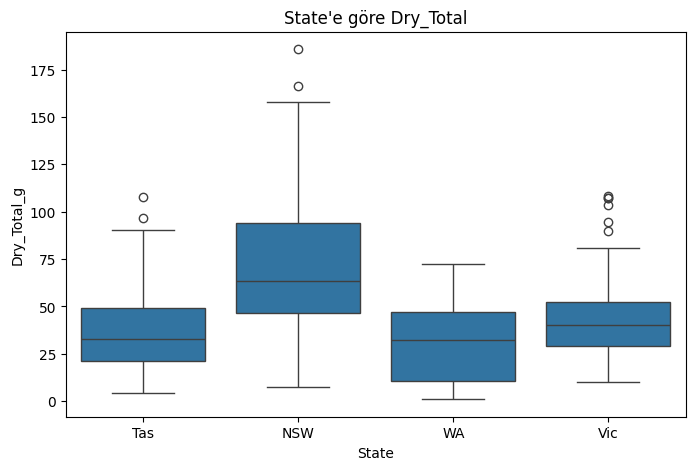

       Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
State                                                           
NSW           53.5         8.4           0.0   53.5         63.3
Tas           13.0        11.1           1.1   18.3         32.8
Vic           21.6         7.2           4.1   27.9         40.2
WA             0.4         0.0          15.6   32.3         32.3


In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="State", y="Dry_Total_g")
plt.title("State'e göre Dry_Total")
plt.show()

print(df.groupby("State")[TARGETS].median().round(1))

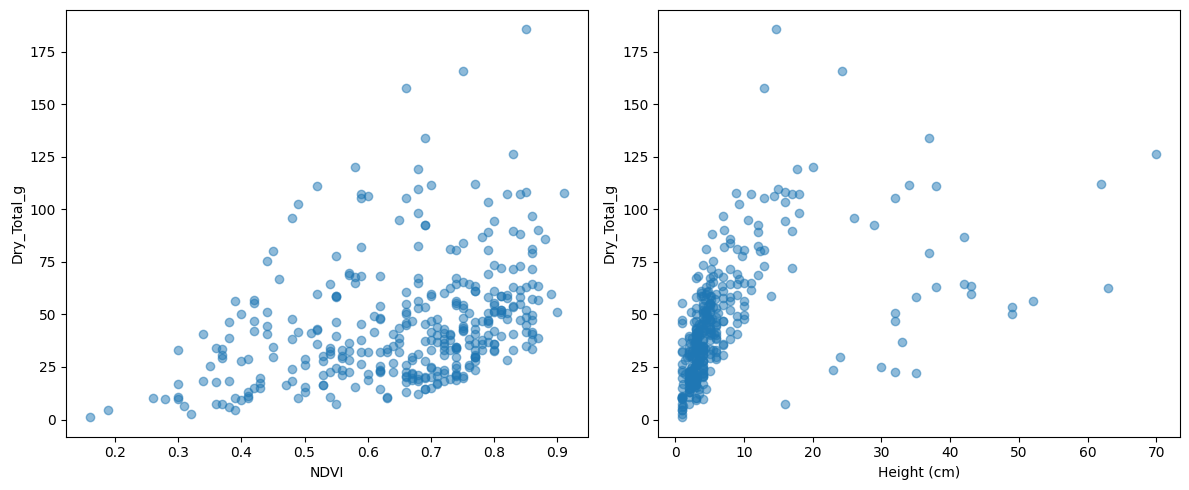

               Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
Pre_GSHH_NDVI         0.45       -0.12          0.14   0.59         0.42
Height_Ave_cm         0.80        0.21         -0.45   0.69         0.73


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(df["Pre_GSHH_NDVI"], df["Dry_Total_g"], alpha=0.5)
ax[0].set_xlabel("NDVI")
ax[0].set_ylabel("Dry_Total_g")

ax[1].scatter(df["Height_Ave_cm"], df["Dry_Total_g"], alpha=0.5)
ax[1].set_xlabel("Height (cm)")
ax[1].set_ylabel("Dry_Total_g")

plt.tight_layout()
plt.show()

cols = ["Pre_GSHH_NDVI", "Height_Ave_cm"]
corr = df[cols + TARGETS].corr(method="spearman")
print(corr.loc[cols, TARGETS].round(2))

**Yorum:**
- Örnek sayıları State'e göre dengesiz: Tas 138, Vic 112, NSW 75, WA 32. 15 farklı tür var, en çok Ryegrass_Clover.
- NSW'de biomass belirgin şekilde yüksek (medyan Total 63 g, Tas'ta 33 g). WA örneklerinde neredeyse sadece Clover var.
- Height ile Total arasında güçlü ilişki var (0.73), NDVI'da daha zayıf (0.42).
- Aynı yerden ve tarihten gelen fotoğraflar birbirine benzediği için CV'de GroupKFold kullanacağız.

## 5. Görüntü Analizi

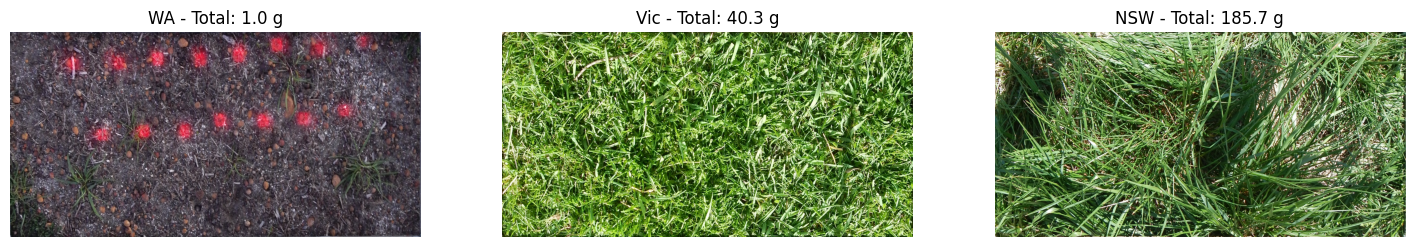

In [12]:
from PIL import Image

s = df.sort_values("Dry_Total_g")
ornekler = [s.iloc[0], s.iloc[len(s) // 2], s.iloc[-1]]

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for i, row in enumerate(ornekler):
    img = Image.open(f"data/{row.image_path}")
    ax[i].imshow(img)
    ax[i].set_title(f"{row.State} - Total: {row.Dry_Total_g:.1f} g")
    ax[i].axis("off")
plt.show()

In [13]:
boyutlar = [Image.open(f"data/{p}").size for p in df["image_path"]]
print(pd.Series(boyutlar).value_counts())

(2000, 1000)    357
Name: count, dtype: int64


In [14]:
r, g, b = [], [], []
for p in df["image_path"]:
    img = np.array(Image.open(f"data/{p}").resize((200, 100))) / 255
    r.append(img[:, :, 0].mean())
    g.append(img[:, :, 1].mean())
    b.append(img[:, :, 2].mean())

df["r"], df["g"], df["b"] = r, g, b
df["yesillik"] = df["g"] / (df["r"] + df["g"] + df["b"])

corr = df[["r", "g", "b", "yesillik"] + TARGETS].corr(method="spearman")
print(corr.loc[["r", "g", "b", "yesillik"], TARGETS].round(2))

          Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
r               -0.18        0.25         -0.10  -0.32        -0.17
g                0.27       -0.04          0.07   0.23         0.14
b               -0.18        0.05         -0.30  -0.32        -0.22
yesillik         0.40       -0.10          0.22   0.53         0.37


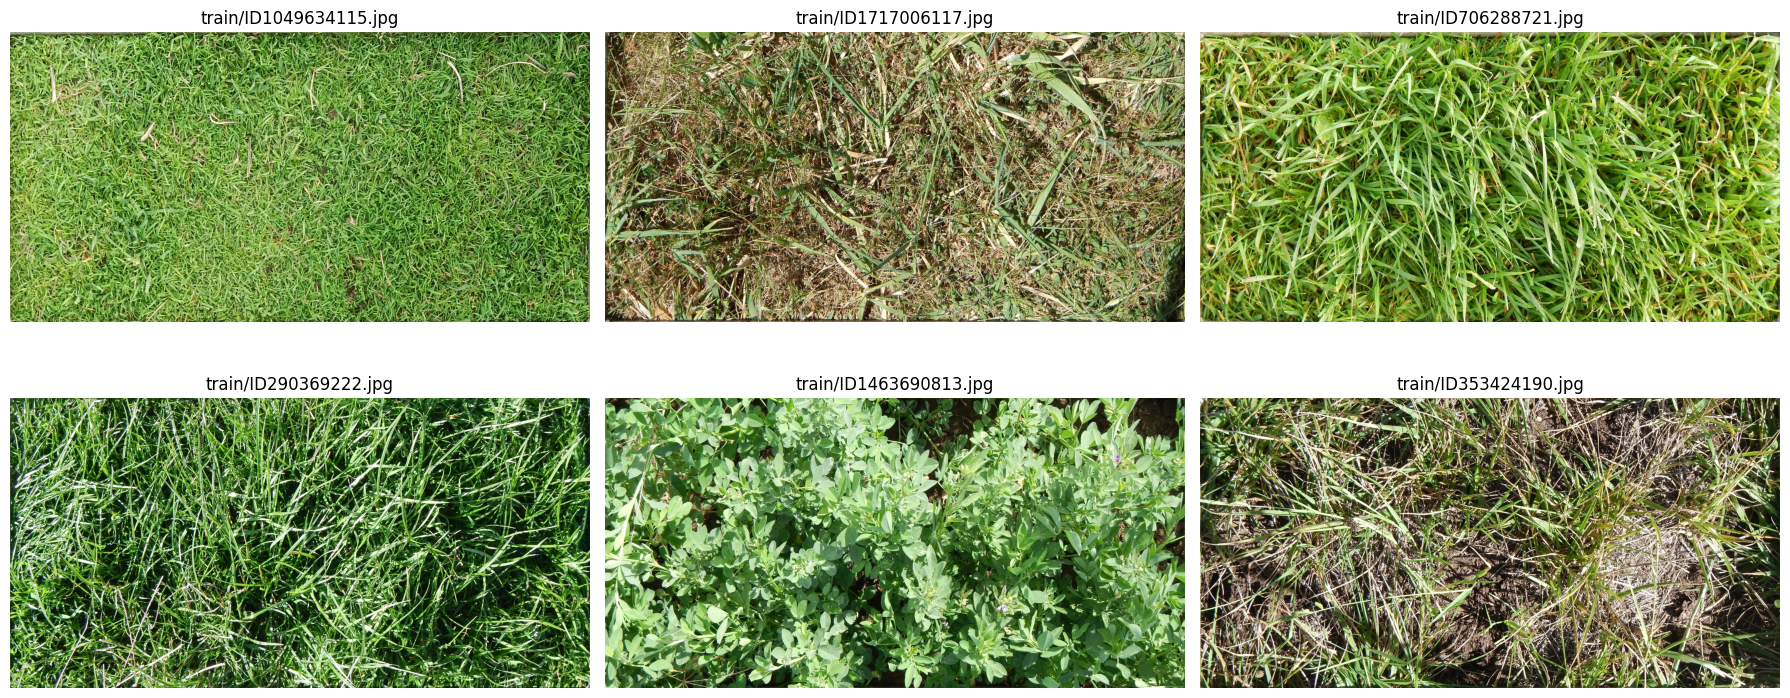

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8))
for a, p in zip(ax.flat, df["image_path"].sample(6, random_state=0)):
    a.imshow(Image.open(f"data/{p}"))
    a.set_title(p)
    a.axis("off")
plt.tight_layout()
plt.show()

**Yorum:**
- Tüm görüntüler 2000x1000, boyut farkı yok.
- Düşük biomass örnekleri neredeyse çıplak toprak, yüksek olanlar uzun ve sık çim. Bazı fotoğraflarda kırmızı lazer noktaları ve kenarlarda koyu çerçeve var.
- Basit yeşillik oranı bile GDM ile 0.53 korelasyonlu. Renk özellikleri baseline için işe yarar.
- Kuru ot ile toprak renk olarak çok benziyor, Dry_Dead'i tahmin etmek zor olabilir.

## 6. Mevsim Analizi

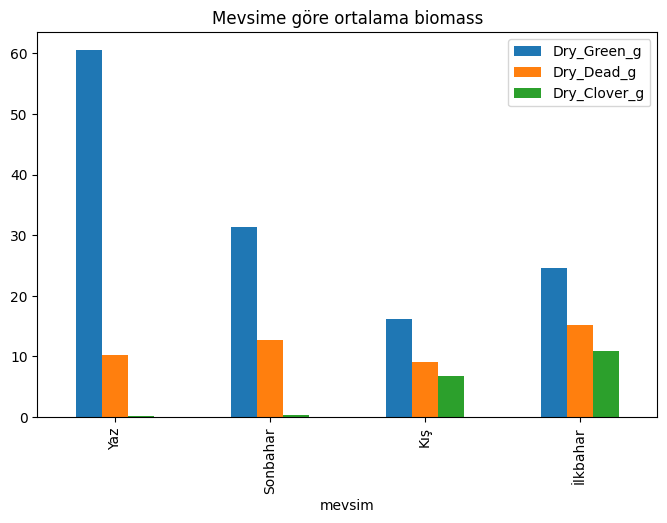

mevsim  Yaz  Sonbahar  Kış  İlkbahar
State                               
NSW      41        23    0        11
Tas       0        29   38        71
Vic       0         0   73        39
WA        0         0   20        12


In [16]:
df["ay"] = pd.to_datetime(df["Sampling_Date"]).dt.month

# Avustralya güney yarımkürede, mevsimler ters
mevsim = {12: "Yaz", 1: "Yaz", 2: "Yaz",
          3: "Sonbahar", 4: "Sonbahar", 5: "Sonbahar",
          6: "Kış", 7: "Kış", 8: "Kış",
          9: "İlkbahar", 10: "İlkbahar", 11: "İlkbahar"}
df["mevsim"] = df["ay"].map(mevsim)
sira = ["Yaz", "Sonbahar", "Kış", "İlkbahar"]

ort = df.groupby("mevsim")[["Dry_Green_g", "Dry_Dead_g", "Dry_Clover_g"]].mean().loc[sira]
ort.plot.bar(figsize=(8, 5), title="Mevsime göre ortalama biomass")
plt.show()

print(pd.crosstab(df["State"], df["mevsim"])[sira])

**Yorum:**
- Yazın Green yüksek, Clover neredeyse sıfır. Clover sadece kış ve ilkbaharda var.
- Ama yaz örneklerinin hepsi NSW'den, Vic ve WA'da hiç yaz örneği yok. Mevsim etkisi ile konum etkisi birbirine karışmış, bu farkı sadece mevsime bağlayamayız.
- Bu da GroupKFold kararını destekliyor: modelin konum/zaman ezberlemesini engellememiz lazım.

## 7. Bitki Örtüsü Oranı
Yeşil piksel: G kanalı R ve B'den büyük olan piksel. Örtü oranı = yeşil piksellerin oranı.
Aynı döngüde sol ve sağ yarının örtü oranını da hesaplıyoruz.

In [17]:
ortu, sol, sag = [], [], []
for p in df["image_path"]:
    img = np.array(Image.open(f"data/{p}").resize((200, 100))).astype(float)
    r, g, b = img[:, :, 0], img[:, :, 1], img[:, :, 2]
    yesil = (g > r) & (g > b)
    ortu.append(yesil.mean())
    sol.append(yesil[:, :100].mean())
    sag.append(yesil[:, 100:].mean())

df["ortu"], df["sol"], df["sag"] = ortu, sol, sag

corr = df[["ortu", "yesillik"] + TARGETS].corr(method="spearman")
print(corr.loc[["ortu", "yesillik"], TARGETS].round(2))

          Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
ortu             0.45        -0.2          0.16   0.56         0.36
yesillik         0.40        -0.1          0.22   0.53         0.37


**Yorum:**
- Yeşil örtü oranı GDM ile 0.56 korelasyonlu, basit yeşillikten (0.53) biraz daha iyi.
- Birçok görüntüde örtü 1.0'a dayanıyor: zemin tamamen kaplanınca örtü artık artmıyor. Yani renk, sık ile çok sık çayırı ayıramıyor. Yükseklik/doku bilgisi gerekecek.

## 8. Sol ve Sağ Yarı Karşılaştırması

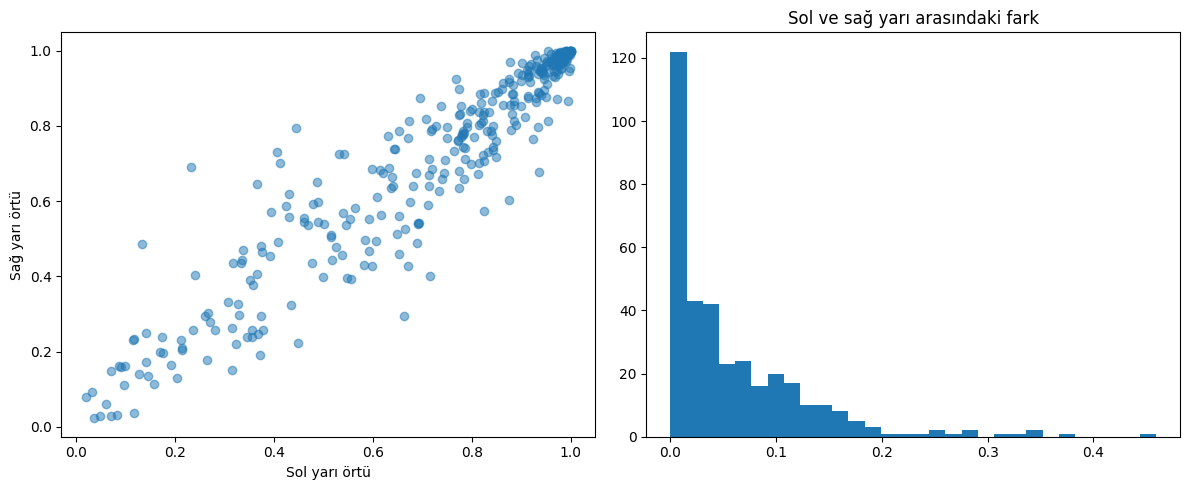

Sol-sağ korelasyon: 0.95
Farkı 0.2'den büyük görüntü oranı: 0.04


In [18]:
fark = (df["sol"] - df["sag"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(df["sol"], df["sag"], alpha=0.5)
ax[0].set_xlabel("Sol yarı örtü")
ax[0].set_ylabel("Sağ yarı örtü")
ax[1].hist(fark, bins=30)
ax[1].set_title("Sol ve sağ yarı arasındaki fark")
plt.tight_layout()
plt.show()

print("Sol-sağ korelasyon:", round(df["sol"].corr(df["sag"]), 2))
print("Farkı 0.2'den büyük görüntü oranı:", round((fark > 0.2).mean(), 2))

**Yorum:**
- Sol ve sağ yarı çok benzer (korelasyon 0.95, farkı 0.2'den büyük olan görüntü sadece %4).
- Görüntüyü ikiye bölmenin faydası farklılıktan değil, yüksek çözünürlüğü korumaktan gelir.

## 9. EDA Özeti: Modelleme İçin Çıkarımlar
- Veri temiz: eksik, tekrar eden ya da negatif değer yok. Aykırı değerler gerçek ölçümler.
- Hedefler sağa çarpık. Log1p ölçeğinde eğitip expm1 ile geri çevireceğiz, negatif tahminleri 0'a kırpacağız.
- Total ve GDM diğer hedeflerin toplamı. Tahminleri bu ilişkiye uyduran bir düzeltme denenebilir.
- Metadata test'te yok, modeller sadece görüntüyü kullanacak.
- Konum ve mevsim birbirine karışmış, aynı State/tarih grupları benzer. Bu yüzden GroupKFold ile 5 fold CV yapacağız.
- Renk ve örtü özellikleri biomass ile orta düzeyde ilişkili ama yoğun çayırlarda doyuyor. Doku görebilen modeller (pretrained CNN) gerekecek.
- Görüntüler 2:1 oranlı. Küçültürken detay kaybolmasın diye sol/sağ ikiye bölmek mantıklı.
- En zor hedefler Clover (çok sıfır var, mevsime bağlı) ve Dead (toprağa benziyor).